# IRWA Final Project – Part 3: Ranking and Filtering

This notebook builds on Part 1 (text processing) and Part 2 (inverted index, conjunctive search), and it implements:

1. Conjunctive (AND) retrieval over the inverted index.
2. Four ways of ranking the AND matches: **TF-IDF + cosine**, **BM25**, **our own score** and **Word2Vec + cosine**.
3. The top-20 list of the five test queries from Part 2 for every method.
4. A comparison of the rankings (overlap, rank correlation) and the evaluation on the two validation queries with the Part 2 metrics.
5. A discussion of better text representations than averaged Word2Vec (Doc2Vec, Sentence2Vec, transformers).

Run the cells from top to bottom. Paths are relative to `project_progress/part_3/`.

## 0. Setup and paths

In [1]:
import json
import re
import math
import matplotlib.pyplot as plt
import os
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords", quiet=True)
STOPWORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()

# Paths relative to project_progress/part_3/ (data/ at the repository root).
# Change them only if your data files are somewhere else.
DATA_PATH = "fashion_products_dataset.json"
LABELS_PATH = "validation_labels.csv"
OUT_DIR = "data"          # where the top-20 CSV files are written

SEED = 42
np.random.seed(SEED)

## 1. Pre-processing (PART 1)

Identical to Parts 1 and 2, so that the index terms and the query terms go through exactly the same pipeline.

In [2]:
DOMAIN_STOPWORDS = set()  # empty by decision (see Part 1 report)


def tokenize(text):
    """Lowercase and split into alphanumeric tokens."""
    if not text:
        return []
    return re.findall(r"[a-z0-9]+", str(text).lower())


def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS and t not in DOMAIN_STOPWORDS]


def stem_tokens(tokens):
    return [STEMMER.stem(t) for t in tokens]


def preprocess_text(text):
    """tokenize -> remove stop words -> Porter stemming."""
    return stem_tokens(remove_stopwords(tokenize(text)))


def product_details_to_text(details):
    """[{"Color": "Blue"}, ...] -> "Color Blue ..."."""
    if not details:
        return ""
    parts = []
    for item in details:
        if isinstance(item, dict):
            for key, value in item.items():
                parts.append(f"{key} {value}")
        else:
            parts.append(str(item))
    return " ".join(parts)


def parse_price(value):
    if value is None:
        return None
    try:
        return float(str(value).replace(",", "").strip())
    except ValueError:
        return None


def parse_discount(value):
    if not value:
        return None
    match = re.search(r"(\d+(?:\.\d+)?)\s*%", str(value))
    return float(match.group(1)) if match else None


def parse_rating(value):
    if value is None or str(value).strip() == "":
        return None
    try:
        return float(value)
    except ValueError:
        return None


def parse_bool(value):
    if isinstance(value, bool):
        return value
    if value is None:
        return None
    text = str(value).strip().lower()
    if text in {"true", "1", "yes"}:
        return True
    if text in {"false", "0", "no"}:
        return False
    return None

## 2. Inverted index

Same index as Part 2 (all three text fields in one bag of terms, doc_id = pid), with three additions needed by the new scores:

- doc_len: number of tokens of the document (needed by BM25).
- title_terms: set of terms that appear in the title (used by our own score).
- numeric: rating, discount, selling price and stock status (used by our own score).

We also keep the token list of every document, which is the training corpus of Word2Vec.

In [3]:
with open(DATA_PATH, encoding="utf-8") as f:
    raw_docs = json.load(f)

N = len(raw_docs)
index = defaultdict(dict)   # term -> {pid: raw tf}
doc_len = {}                # pid -> number of tokens
doc_tokens = {}             # pid -> list of tokens (Word2Vec corpus)
title_terms = {}            # pid -> set of title terms
numeric = {}                # pid -> numeric metadata
display = {}                # pid -> fields shown in the results

for raw in raw_docs:
    pid = raw["pid"]
    title_t = preprocess_text(raw.get("title"))
    tokens = (title_t + preprocess_text(raw.get("description")) + preprocess_text(product_details_to_text(raw.get("product_details"))))
    for term, count in Counter(tokens).items():
        index[term][pid] = count
    doc_len[pid] = len(tokens)
    doc_tokens[pid] = tokens
    title_terms[pid] = set(title_t)
    numeric[pid] = {
        "rating": parse_rating(raw.get("average_rating")),
        "discount": parse_discount(raw.get("discount")),
        "price": parse_price(raw.get("selling_price")),
        "out_of_stock": bool(parse_bool(raw.get("out_of_stock"))),
    }
    display[pid] = {k: raw.get(k) for k in
                    ["title", "brand", "sub_category", "selling_price", "average_rating", "out_of_stock", "url"]}

AVGDL = float(np.mean(list(doc_len.values())))
print("Documents indexed:", N)
print("Distinct terms in the index:", len(index))
print(f"Average document length: {AVGDL:.1f} tokens")

Documents indexed: 28080
Distinct terms in the index: 20426
Average document length: 68.2 tokens


## 3. Conjunctive (AND) retrieval

A document is a candidate only if it contains all of the (pre-processed) query terms. The ranking functions below only score these candidates, so every method returns the same set of documents in a different order. The filter is the same function as in Part 2.

In [4]:
def search_and(query):
    """Return (list of pids containing ALL query terms, list of unique query terms)."""
    terms = list(dict.fromkeys(preprocess_text(query)))  # unique terms, in order
    if not terms:
        return [], terms
    postings = [set(index.get(t, {}).keys()) for t in terms]
    if any(len(p) == 0 for p in postings):
        return [], terms  # one term does not occur at all: no document can match
    return list(set.intersection(*postings)), terms

## 4. EXERCISE 1: Ranking method 1: TF-IDF + cosine similarity

- Document weight of a term: (1 + ln tf) * idf, with idf = ln(N / df) (as in Part 2).
- Query weight of a term: (count in query) * idf.
- Score: cosine between the query vector and the document vector. The document norm is computed over all the terms of the document (a real cosine), whereas Part 2 normalised the raw term frequencies only.
- Sub-linear term frequency (1 + ln tf) so that a term repeated 20 times does not weigh 20 times more than one appearing once.

In [5]:
def idf(term):
    df_t = len(index.get(term, {}))
    return math.log(N / df_t) if df_t else 0.0


# Pre-computed norm of every document's TF-IDF vector (over all its terms)
_sq = defaultdict(float)
for _t, _postings in index.items():
    _idf = idf(_t)
    for _pid, _tf in _postings.items():
        _sq[_pid] += ((1 + math.log(_tf)) * _idf) ** 2
doc_tfidf_norm = {pid: math.sqrt(v) or 1.0 for pid, v in _sq.items()}
del _sq


def rank_tfidf(query):
    """List of (pid, cosine score) for the AND matches, best first."""
    matches, terms = search_and(query)
    if not matches:
        return []
    q_tf = Counter(preprocess_text(query))
    q_w = {t: c * idf(t) for t, c in q_tf.items() if t in index}
    q_norm = math.sqrt(sum(w * w for w in q_w.values())) or 1.0
    scores = {}
    for pid in matches:
        dot = sum(w * (1 + math.log(index[t][pid])) * idf(t) for t, w in q_w.items())
        scores[pid] = dot / (q_norm * doc_tfidf_norm[pid])
    return sorted(scores.items(), key=lambda x: (-x[1], x[0]))

## 5. Ranking method 2: BM25

Okapi BM25 with the usual parameters k1 = 1.2, b = 0.75 and the non-negative idf ln(1 + (N - df + 0.5) / (df + 0.5)):

score(q, d) = sum over t in q of idf(t) * tf * (k1 + 1) / (tf + k1 * (1 - b + b * |d| / avgdl))

Unlike TF-IDF/cosine, the term-frequency contribution saturates (controlled by k1) and the document length is handled by b instead of a vector norm.

In [6]:
K1, B = 1.2, 0.75


def bm25_idf(term):
    df_t = len(index.get(term, {}))
    return math.log(1 + (N - df_t + 0.5) / (df_t + 0.5)) if df_t else 0.0


def bm25_scores(terms, matches, k1=K1, b=B):
    """Dict pid -> BM25 score for the given (unique) query terms."""
    scores = {}
    for pid in matches:
        norm = k1 * (1 - b + b * doc_len[pid] / AVGDL)
        s = 0.0
        for t in terms:
            tf = index[t][pid]
            s += bm25_idf(t) * tf * (k1 + 1) / (tf + norm)
        scores[pid] = s
    return scores


def rank_bm25(query, k1=K1, b=B):
    matches, terms = search_and(query)
    if not matches:
        return []
    scores = bm25_scores(terms, matches, k1, b)
    return sorted(scores.items(), key=lambda x: (-x[1], x[0]))

tf                   1     2     5     10
TF-IDF: 1 + ln tf   1.0  1.69  2.61  3.30
BM25 (|d| = avgdl)  1.0  1.38  1.77  1.96 

BM25, tf = 1, |d| = 0.25 x avgdl (17 tokens): 1.44
BM25, tf = 1, |d| = 1.0 x avgdl (68 tokens): 1.00
BM25, tf = 1, |d| = 4.0 x avgdl (273 tokens): 0.45


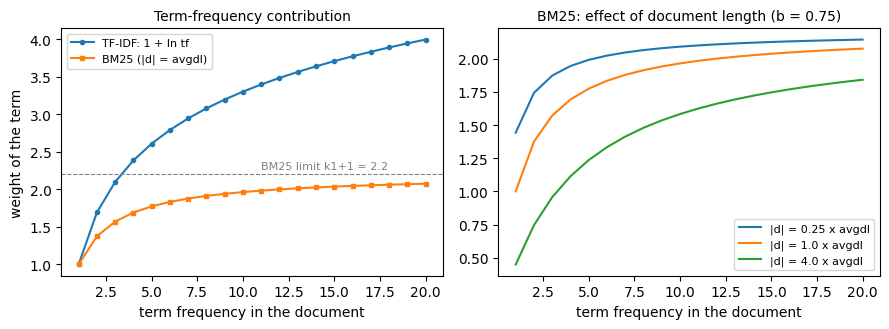

In [7]:
# Weight of ONE term (before multiplying by idf) as a function of its frequency in the document.
# TF-IDF uses 1 + ln(tf); BM25 uses tf*(k1+1) / (tf + k1*(1 - b + b*|d|/avgdl)).
def tfidf_tf_weight(tf):
    return 1 + math.log(tf)


def bm25_tf_weight(tf, length_ratio=1.0, k1=K1, b=B):
    """length_ratio = |d| / avgdl (1.0 = document of average length)."""
    return tf * (k1 + 1) / (tf + k1 * (1 - b + b * length_ratio))


# Table: effect of the term frequency (document of average length)
tf_values = [1, 2, 5, 10]
tf_table = pd.DataFrame(
    {"TF-IDF: 1 + ln tf": [tfidf_tf_weight(t) for t in tf_values],
     "BM25 (|d| = avgdl)": [bm25_tf_weight(t) for t in tf_values]},
    index=pd.Index(tf_values, name="tf"),
).T.round(2)
print(tf_table, "\n")

# Effect of the document length for one occurrence (tf = 1)
for ratio in [0.25, 1.0, 4.0]:
    print(f"BM25, tf = 1, |d| = {ratio} x avgdl ({ratio * AVGDL:.0f} tokens): {bm25_tf_weight(1, ratio):.2f}")

# Figure
tfs = np.arange(1, 21)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(tfs, [tfidf_tf_weight(t) for t in tfs], marker="o", ms=3, label="TF-IDF: 1 + ln tf")
ax[0].plot(tfs, [bm25_tf_weight(t) for t in tfs], marker="s", ms=3, label="BM25 (|d| = avgdl)")
ax[0].axhline(K1 + 1, ls="--", lw=0.8, c="grey")
ax[0].text(11, K1 + 1 + 0.07, f"BM25 limit k1+1 = {K1 + 1:.1f}", fontsize=8, color="grey")
ax[0].set_xlabel("term frequency in the document")
ax[0].set_ylabel("weight of the term")
ax[0].set_title("Term-frequency contribution", fontsize=10)
ax[0].legend(fontsize=8)
for ratio in [0.25, 1.0, 4.0]:
    ax[1].plot(tfs, [bm25_tf_weight(t, ratio) for t in tfs], label=f"|d| = {ratio} x avgdl")
ax[1].set_xlabel("term frequency in the document")
ax[1].set_title(f"BM25: effect of document length (b = {B})", fontsize=10)
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part3_tf_bm25.png"), dpi=200)
plt.show()

## 6. Ranking method 3: our own score

Text relevance alone says nothing about how good a product is. All the AND matches already contain every query word, so we can use the numeric fields of the record to decide the order among them:

score = stock_factor * ( w_text * BM25_norm + w_title * title_coverage + w_rating * rating_norm + w_disc * discount_norm )

| Component | Definition | Why |
|---|---|---|
| BM25_norm | BM25 divided by the maximum BM25 among the matches of the query (in [0, 1]) | keeps text relevance as the main signal and makes it comparable with the other components |
| title_coverage | fraction of the query terms that appear in the title | a product whose title contains "jeans" is more about jeans than one that mentions it in a long description (the index does not keep fields, so this recovers part of that information) |
| rating_norm | average_rating / 5; if missing, the mean rating of the catalogue | prefers products other customers rated well; a missing rating gets a neutral value instead of a penalty |
| discount_norm | discount / 100 (0 if missing) | small bonus for discounted products |
| stock_factor | 0.5 if out_of_stock, else 1 | users cannot buy an unavailable product, so it is pushed down but not removed |

Default weights: w_text = 0.60, w_title = 0.20, w_rating = 0.15, w_disc = 0.05. They are explicit parameters and can be changed in CUSTOM_WEIGHTS.

In [8]:
CUSTOM_WEIGHTS = {"text": 0.60, "title": 0.20, "rating": 0.15, "discount": 0.05}
OUT_OF_STOCK_FACTOR = 0.5

_ratings = [v["rating"] for v in numeric.values() if v["rating"] is not None]
MEAN_RATING = float(np.mean(_ratings)) if _ratings else 3.0
print(f"Mean catalogue rating (used for missing ratings): {MEAN_RATING:.2f}")


def rank_custom(query, weights=None, oos_factor=OUT_OF_STOCK_FACTOR):
    """Our own score: BM25 + title coverage + rating + discount, penalising out-of-stock products."""
    w = weights or CUSTOM_WEIGHTS
    matches, terms = search_and(query)
    if not matches:
        return []
    bm = bm25_scores(terms, matches)
    bm_max = max(bm.values()) or 1.0
    scores = {}
    for pid in matches:
        meta = numeric[pid]
        title_cov = sum(t in title_terms[pid] for t in terms) / len(terms)
        rating = meta["rating"] if meta["rating"] is not None else MEAN_RATING
        discount = meta["discount"] if meta["discount"] is not None else 0.0
        s = (w["text"] * bm[pid] / bm_max
             + w["title"] * title_cov
             + w["rating"] * rating / 5.0
             + w["discount"] * min(discount, 100.0) / 100.0)
        scores[pid] = s * (oos_factor if meta["out_of_stock"] else 1.0)
    return sorted(scores.items(), key=lambda x: (-x[1], x[0]))

Mean catalogue rating (used for missing ratings): 3.63


## 7. EXERCISE 2: Ranking method 4: Word2Vec + cosine similarity

We train Word2Vec (skip-gram) on the pre-processed token lists of the catalogue (the same terms as the index, so query and document vectors live in the same vocabulary). A text is represented by the **average of the vectors of its words**; the score is the cosine between the query vector and the document vector. As in the other methods, only the AND matches are ranked.

Decisions: 100 dimensions, window 5, min_count = 2 (words seen once cannot get a reliable vector), 15 epochs, a fixed seed and a single worker so that the result is reproducible. Terms that are not in the Word2Vec vocabulary are skipped when averaging.

In [9]:
from gensim.models import Word2Vec

w2v = Word2Vec(
    sentences=list(doc_tokens.values()),
    vector_size=100, window=5, min_count=2, sg=1,
    epochs=15, workers=1, seed=SEED,
)
kv = w2v.wv
print("Word2Vec vocabulary:", len(kv.key_to_index), "terms")
print("Most similar to 'jean':", [t for t, _ in kv.most_similar("jean", topn=5)] if "jean" in kv else "n/a")

Word2Vec vocabulary: 7828 terms
Most similar to 'jean': ['denim', 'skinni', 'trouser', 'washblu', 'carbon']


In [10]:
def text_vector(tokens):
    """Average of the word vectors of the tokens known to the model (None if there are none)."""
    vecs = [kv[t] for t in tokens if t in kv.key_to_index]
    return np.mean(vecs, axis=0) if vecs else None


_doc_vec_cache = {}


def doc_vector(pid):
    if pid not in _doc_vec_cache:
        _doc_vec_cache[pid] = text_vector(doc_tokens[pid])
    return _doc_vec_cache[pid]


def cosine(a, b):
    if a is None or b is None:
        return 0.0
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.dot(a, b) / denom) if denom else 0.0


def rank_word2vec(query):
    """AND matches ranked by cosine(mean word2vec of the query, mean word2vec of the document)."""
    matches, terms = search_and(query)
    if not matches:
        return []
    q_vec = text_vector(preprocess_text(query))
    scores = {pid: cosine(q_vec, doc_vector(pid)) for pid in matches}
    return sorted(scores.items(), key=lambda x: (-x[1], x[0]))

## 8. Five test queries: top-20 of every method

The five queries are the ones defined in Part 2. One CSV per method is written to OUT_DIR.

In [11]:
TEST_QUERIES = [
    "men polo shirt",
    "women printed kurta",
    "blue slim jeans",
    "women sweatshirt cotton",
    "men track pants",
]

RANKERS = {
    "tfidf": rank_tfidf,
    "bm25": rank_bm25,
    "custom": rank_custom,
    "word2vec": rank_word2vec,
}

for q in TEST_QUERIES:
    matches, terms = search_and(q)
    print(f"{q!r:30s} terms={terms}  AND matches={len(matches)}")

'men polo shirt'               terms=['men', 'polo', 'shirt']  AND matches=1466
'women printed kurta'          terms=['women', 'print', 'kurta']  AND matches=42
'blue slim jeans'              terms=['blue', 'slim', 'jean']  AND matches=442
'women sweatshirt cotton'      terms=['women', 'sweatshirt', 'cotton']  AND matches=513
'men track pants'              terms=['men', 'track', 'pant']  AND matches=877


In [12]:
def show_top(query, method, top=20):
    ranked = RANKERS[method](query)
    print(f"=== {method.upper()} | {query!r} | {len(ranked)} matches, top {min(top, len(ranked))} ===")
    for rank, (pid, score) in enumerate(ranked[:top], start=1):
        d = display[pid]
        print(f"{rank:2d}. {score:.4f} | {pid} | rating={d['average_rating']!s:>4} | "
              f"oos={d['out_of_stock']!s:5} | {d['title']}")
    print()


show_top("women sweatshirt cotton", "word2vec")   # example; change query/method freely

=== WORD2VEC | 'women sweatshirt cotton' | 513 matches, top 20 ===
 1. 0.8126 | SWSFW6KB8GZHEC72 | rating= 3.6 | oos=False | Full Sleeve Color Block Women Sweatshirt
 2. 0.8091 | SWSFWG9BCZG4GZVP | rating= 3.6 | oos=False | Full Sleeve Color Block Women Sweatshirt
 3. 0.8081 | SWSFWG9BXMPKGAGK | rating= 3.6 | oos=False | Full Sleeve Color Block Women Sweatshirt
 4. 0.8081 | SWSFWG9B8HFE6SGK | rating= 3.6 | oos=False | Full Sleeve Color Block Women Sweatshirt
 5. 0.8081 | SWSFWG9BTRDCWR2S | rating= 3.6 | oos=False | Full Sleeve Color Block Women Sweatshirt
 6. 0.8080 | SWSFWG9BZMUHEFHS | rating= 3.6 | oos=False | Full Sleeve Color Block Women Sweatshirt
 7. 0.8072 | SWSFWG9BJ5U5BRBU | rating= 3.6 | oos=False | Full Sleeve Color Block Women Sweatshirt
 8. 0.8070 | SWSFWG9BHYUMNSPG | rating= 3.6 | oos=False | Full Sleeve Color Block Women Sweatshirt
 9. 0.8067 | SWSFWG9BAP5FGWG4 | rating= 3.6 | oos=False | Full Sleeve Color Block Women Sweatshirt
10. 0.8061 | SWSFW6BQ74JCVHHH | rating= 3.

In [13]:
top20_rows = []
for method, fn in RANKERS.items():
    for q in TEST_QUERIES:
        for rank, (pid, score) in enumerate(fn(q)[:20], start=1):
            d = display[pid]
            top20_rows.append({"method": method, "query": q, "rank": rank, "pid": pid,
                               "score": round(score, 4), "title": d["title"],
                               "rating": d["average_rating"], "out_of_stock": d["out_of_stock"]})
top20 = pd.DataFrame(top20_rows)
os.makedirs(OUT_DIR, exist_ok=True)
for method in RANKERS:
    path = os.path.join(OUT_DIR, f"part3_top20_{method}.csv")
    top20[top20["method"] == method].to_csv(path, index=False)
    print("written", path)
top20[top20["method"] == "word2vec"].head(20)

written data\part3_top20_tfidf.csv
written data\part3_top20_bm25.csv
written data\part3_top20_custom.csv
written data\part3_top20_word2vec.csv


,method,query,rank,pid,score,title,rating,out_of_stock
300,word2vec,men polo shirt,1,TSHFWCPHK7J5H2UU,0.7334,Solid Men Polo Neck Green T-Shirt,4,False
301,word2vec,men polo shirt,2,TSHFWCPHA8JF4HDV,0.7316,Solid Men Polo Neck Blue T-Shirt,4,False
302,word2vec,men polo shirt,3,TSHFWCPH77RAYAFF,0.7315,Solid Men Polo Neck White T-Shirt,4,False
303,word2vec,men polo shirt,4,TSHFWVYDD2G5USN6,0.7313,Solid Men Polo Neck Maroon T-Shirt,4.5,False
304,word2vec,men polo shirt,5,TSHFWCPHW85DNJFF,0.7311,Solid Men Polo Neck Red T-Shirt,4,False
305,word2vec,men polo shirt,6,TSHFWCPHVBZRCCYQ,0.7310,Solid Men Polo Neck Blue T-Shirt,4,False
306,word2vec,men polo shirt,7,TSHFWCPHY7FJ4RHU,0.7306,Solid Men Polo Neck Maroon T-Shirt,4,False
307,word2vec,men polo shirt,8,TSHFWCPHJXZHYPNP,0.7306,Solid Men Polo Neck Beige T-Shirt,4,False
308,word2vec,men polo shirt,9,TSHFWJZEBEGPHCTH,0.7304,Solid Men Polo Neck Grey T-Shirt,4,False
309,word2vec,men polo shirt,10,TSHFWJZEH8ERSCHN,0.7300,Solid Men Polo Neck Maroon T-Shirt,4,False


## 9. How do the rankings differ?

For each test query we compare the methods with (a) the overlap of their top-10 lists and (b) the Spearman rank correlation over **all** the AND matches. Because the match set is the same, the correlation only measures the change of order.

In [14]:
def top_overlap(r1, r2, k=10):
    a, b = {p for p, _ in r1[:k]}, {p for p, _ in r2[:k]}
    return len(a & b) / max(1, min(k, len(a), len(b)))


def spearman(r1, r2):
    s1 = pd.Series({p: i for i, (p, _) in enumerate(r1)})
    s2 = pd.Series({p: i for i, (p, _) in enumerate(r2)}).reindex(s1.index)
    return float(s1.corr(s2)) if len(s1) > 1 else float("nan")


METHODS = list(RANKERS)
rows = []
for q in TEST_QUERIES:
    ranks = {m: RANKERS[m](q) for m in METHODS}
    for i, m1 in enumerate(METHODS):
        for m2 in METHODS[i + 1:]:
            rows.append({"query": q, "pair": f"{m1} vs {m2}",
                         "top10_overlap": round(top_overlap(ranks[m1], ranks[m2]), 2),
                         "spearman": round(spearman(ranks[m1], ranks[m2]), 3)})
comparison = pd.DataFrame(rows)
comparison.pivot(index="pair", columns="query", values="top10_overlap")

query,blue slim jeans,men polo shirt,men track pants,women printed kurta,women sweatshirt cotton
pair,,,,,
bm25 vs custom,0.5,0.1,0.5,0.8,0.4
bm25 vs word2vec,0.0,0.1,0.3,0.6,0.0
custom vs word2vec,0.0,0.1,0.0,0.6,0.0
tfidf vs bm25,0.4,0.0,0.1,0.0,0.1
tfidf vs custom,0.0,0.2,0.4,0.1,0.2
tfidf vs word2vec,0.0,0.0,0.0,0.1,0.0


In [15]:
comparison.pivot(index="pair", columns="query", values="spearman")

query,blue slim jeans,men polo shirt,men track pants,women printed kurta,women sweatshirt cotton
pair,,,,,
bm25 vs custom,0.331,0.806,0.907,0.774,0.813
bm25 vs word2vec,0.803,0.771,0.920,0.324,0.585
custom vs word2vec,0.266,0.624,0.861,0.270,0.502
tfidf vs bm25,0.801,0.727,0.938,0.264,0.803
tfidf vs custom,0.444,0.594,0.842,-0.004,0.623
tfidf vs word2vec,0.725,0.649,0.827,-0.151,0.303


In [16]:
# Which kind of products does each method put first? (average over the five test queries, top-10)
profile = []
for m in METHODS:
    vals = {"rating": [], "discount": [], "out_of_stock": [], "doc_len": []}
    for q in TEST_QUERIES:
        for pid, _ in RANKERS[m](q)[:10]:
            nm = numeric[pid]
            if nm["rating"] is not None:
                vals["rating"].append(nm["rating"])
            vals["discount"].append(nm["discount"] or 0)
            vals["out_of_stock"].append(nm["out_of_stock"])
            vals["doc_len"].append(doc_len[pid])
    profile.append({"method": m, **{k: round(float(np.mean(v)), 2) for k, v in vals.items()}})
pd.DataFrame(profile).set_index("method")

,rating,discount,out_of_stock,doc_len
method,,,,
tfidf,3.58,52.84,0.04,46.94
bm25,3.34,55.84,0.02,75.48
custom,4.15,61.70,0.00,74.98
word2vec,3.40,55.10,0.02,82.30


## 10. Evaluation on the validation queries

Same protocol and metric definitions as Part 2 (K = 10; the ranking of each method is restricted to the labelled products; P@K divides by K; R@K uses all labelled relevant products as denominator). With only 20 labelled products per query the differences between methods are small and should be read with care.

In [17]:
def precision_at_k(ranked, k):
    return sum(ranked[:k]) / k


def recall_at_k(ranked, total_relevant, k):
    return 0.0 if total_relevant == 0 else sum(ranked[:k]) / total_relevant


def f1_at_k(ranked, total_relevant, k):
    p, r = precision_at_k(ranked, k), recall_at_k(ranked, total_relevant, k)
    return 0.0 if p + r == 0 else 2 * p * r / (p + r)


def average_precision_at_k(ranked, k):
    hits, precisions = 0, []
    for i, rel in enumerate(ranked[:k], start=1):
        if rel == 1:
            hits += 1
            precisions.append(hits / i)
    return sum(precisions) / hits if hits else 0.0


def reciprocal_rank(ranked, k):
    for i, rel in enumerate(ranked[:k], start=1):
        if rel == 1:
            return 1 / i
    return 0.0


def dcg_at_k(gains, k):
    gains = np.asarray(gains, dtype=float)[:k]
    if gains.size == 0:
        return 0.0
    return float(np.sum((2 ** gains - 1) / np.log2(np.arange(gains.size) + 2)))


def ndcg_at_k(ranked, ideal_gains, k):
    ideal = dcg_at_k(sorted(ideal_gains, reverse=True), k)
    return 0.0 if ideal == 0 else dcg_at_k(ranked, k) / ideal

In [18]:
VALIDATION_QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
labels_df = pd.read_csv(LABELS_PATH)
K = 10

results = {}   # (method, query_id) -> metrics
for method, fn in RANKERS.items():
    for qid, query in VALIDATION_QUERIES.items():
        rel_map = dict(zip(labels_df[labels_df["query_id"] == qid]["pid"],
                           labels_df[labels_df["query_id"] == qid]["labels"]))
        total_relevant = int(sum(rel_map.values()))
        ranked_labels = [int(rel_map[pid]) for pid, _ in fn(query) if pid in rel_map]
        results[(method, qid)] = {
            "P@10": precision_at_k(ranked_labels, K),
            "R@10": recall_at_k(ranked_labels, total_relevant, K),
            "AP@10": average_precision_at_k(ranked_labels, K),
            "F1@10": f1_at_k(ranked_labels, total_relevant, K),
            "RR@10": reciprocal_rank(ranked_labels, K),
            "NDCG@10": ndcg_at_k(ranked_labels, list(rel_map.values()), K),
        }

per_query = pd.DataFrame(results).T.round(3)
per_query.index.names = ["method", "query_id"]
per_query

P@10   R@10  AP@10  F1@10  RR@10  NDCG@10
method   query_id                                           
tfidf    1          1.0  0.769  1.000   0.87    1.0    1.000
         2          0.6  0.600  0.915   0.60    1.0    0.706
bm25     1          1.0  0.769  1.000   0.87    1.0    1.000
         2          0.6  0.600  0.948   0.60    1.0    0.716
custom   1          1.0  0.769  1.000   0.87    1.0    1.000
         2          0.6  0.600  0.948   0.60    1.0    0.716
word2vec 1          1.0  0.769  1.000   0.87    1.0    1.000
         2          0.6  0.600  0.897   0.60    1.0    0.702

In [19]:
summary = []
for method in RANKERS:
    m1, m2 = results[(method, 1)], results[(method, 2)]
    summary.append({
        "method": method,
        "MAP@10": (m1["AP@10"] + m2["AP@10"]) / 2,
        "MRR@10": (m1["RR@10"] + m2["RR@10"]) / 2,
        "P@10": (m1["P@10"] + m2["P@10"]) / 2,
        "R@10": (m1["R@10"] + m2["R@10"]) / 2,
        "F1@10": (m1["F1@10"] + m2["F1@10"]) / 2,
        "NDCG@10": (m1["NDCG@10"] + m2["NDCG@10"]) / 2,
    })
pd.DataFrame(summary).set_index("method").round(3)

,MAP@10,MRR@10,P@10,R@10,F1@10,NDCG@10
method,,,,,,
tfidf,0.958,1.0,0.8,0.685,0.735,0.853
bm25,0.974,1.0,0.8,0.685,0.735,0.858
custom,0.974,1.0,0.8,0.685,0.735,0.858
word2vec,0.949,1.0,0.8,0.685,0.735,0.851


## 11. EXERCISE 3: A better representation than averaged Word2Vec?

Averaged Word2Vec has clear limits for product search:

- **Bag of words:** averaging throws away word order and weights every word equally ("men slim jeans" and "jeans slim men" get the same vector, and a stop-word-like term weighs as much as "jeans").
- **One vector per word:** no context, so "blue" in "royal blue" and in "blue jeans" are the same.
- **Dilution:** long descriptions average hundreds of words, so the vector drifts towards the generic fashion vocabulary and the product-specific terms are lost.
- **Out-of-vocabulary words:** rare words (typos, brand names, style codes) get no vector.
- **Trained on our small catalogue only** (28k short texts), so the embeddings are noisy for rare terms.

Alternatives:

| Representation | Pros | Cons |
|---|---|---|
| **Doc2Vec** (paragraph vectors) | learns one vector per document directly, instead of averaging, so it can capture the document as a whole; same gensim workflow | still needs training on our small corpus; queries are unseen texts, so the query vector must be *inferred* (infer_vector), which is stochastic and slower; sensitive to hyper-parameters |
| **TF-IDF-weighted average of Word2Vec** | cheap fix of the main problem: informative words get more weight than frequent ones | still no word order or context |
| **Sentence2Vec / SIF** (weighted average + removal of the first principal component) | strong simple baseline, no extra training | still a bag of words |
| **Sentence-BERT / transformer embeddings** (e.g. all-MiniLM-L6-v2) | contextual, pre-trained on large corpora (no OOV problem, handles synonyms like "pants/trousers"), best semantic quality | heavier (model download, GPU/CPU cost for 28k documents), harder to explain, may rank semantically similar but not exact products first, and an exact-match filter is still needed |

**Our answer:** yes, a better representation exists. In this setting the best trade-off would be a pre-trained sentence-embedding model (Sentence-BERT) applied to the AND matches (or a hybrid BM25 + embedding score), because it solves the context, weighting and out-of-vocabulary problems without needing a large in-domain training set. Doc2Vec is a reasonable middle step, but with a small corpus and short documents its advantage over a weighted Word2Vec average is not guaranteed, and we would have to verify it on the validation queries.